# Step 3: fixed train/test split
One group-aware split reused by every later experiment. Groups = rows with identical T.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedGroupKFold

from utils import load, COLOR_HIGHLIGHT, get_split, load_split_data

SEED = 42
I, T, Y = load()
res_dir = Path("../results"); res_dir.mkdir(exist_ok=True)
fig_dir = Path("../figures"); fig_dir.mkdir(exist_ok=True)
classes = np.unique(Y)

## 1. Groups (identical T rows)

In [2]:
_, groups = np.unique(T, axis=0, return_inverse=True); groups = groups.ravel()
n_groups = len(np.unique(groups))
print("number of groups:", n_groups)

number of groups: 2075


## 2. Leakage check for a naive stratified random split

In [3]:
tr_n, te_n = train_test_split(np.arange(len(Y)), test_size=0.2, stratify=Y, random_state=SEED)
leak_n = int(np.isin(groups[te_n], groups[tr_n]).sum())
leak_frac = leak_n / len(te_n)
print(f"naive split: {leak_n} of {len(te_n)} test rows have an identical T row in train ({leak_frac:.1%})")

naive split: 112 of 500 test rows have an identical T row in train (22.4%)


## 3. Group-aware split (first fold of StratifiedGroupKFold)

In [4]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(iter(sgkf.split(np.zeros(len(Y)), Y, groups)))
shared = np.intersect1d(groups[train_idx], groups[test_idx])
print("train:", len(train_idx), "test:", len(test_idx), "groups shared:", len(shared))

assert len(np.intersect1d(train_idx, test_idx)) == 0
assert np.array_equal(np.sort(np.concatenate([train_idx, test_idx])), np.arange(len(Y)))
assert len(shared) == 0

ctr = np.array([(Y[train_idx] == c).sum() for c in classes])
cte = np.array([(Y[test_idx] == c).sum() for c in classes])
frac = cte / (ctr + cte)
print("label  train  test  test_frac")
for c, a, b, f in zip(classes, ctr, cte, frac):
    print(f"{c:5d} {a:6d} {b:5d}  {f:.2f}")
print(f"test fraction per class: min {frac.min():.2f}, max {frac.max():.2f}")

big = np.bincount(groups).argmax()
big_rows = groups == big
big_split = "train" if np.isin(np.where(big_rows)[0], train_idx).all() else ("test" if np.isin(np.where(big_rows)[0], test_idx).all() else "mixed")
print(f"largest group: {big_rows.sum()} rows, label {np.unique(Y[big_rows])}, landed in {big_split}")

assert cte.min() >= 5, "a class has fewer than 5 test samples"
np.savez(res_dir / "split.npz", train_idx=train_idx, test_idx=test_idx, groups=groups)

train: 2005 test: 495 groups shared: 0
label  train  test  test_frac
    1     85    18  0.17
    2     61    12  0.16
    3     45    18  0.29
    4     77    16  0.17
    5     78    25  0.24
    6     35    14  0.29
    7     37    12  0.24
    8     61    20  0.25
    9     74    12  0.14
   10     55    13  0.19
   11     55    27  0.33
   12     48    14  0.23
   13     65    15  0.19
   14     59    13  0.18
   15     70     5  0.07
   16     62    19  0.23
   17     58    15  0.21
   18     72    12  0.14
   19     83    14  0.14
   20     71    19  0.21
   21     65    14  0.18
   22     46    12  0.21
   23     42    13  0.24
   24     83    19  0.19
   25     52    18  0.26
   26     63    18  0.22
   27     62    16  0.21
   28     49    13  0.21
   29     82    11  0.12
   30     91    17  0.16
   34    119    31  0.21
test fraction per class: min 0.07, max 0.33
largest group: 30 rows, label [9], landed in train


## 5. Sanity checks

In [5]:
d = load_split_data()
tr2, te2, g2 = get_split()
assert np.array_equal(tr2, train_idx) and np.array_equal(te2, test_idx)
dI = float(np.abs(d["I_mean"] - I.mean(0)).max())
dT = float(np.abs(d["T_mean"] - T.mean(0)).max())
print(f"max |train mean - full mean|: I {dI:.2e}, T {dT:.2e}")
print("I scale (mean abs value):", np.abs(I).mean(), " T:", np.abs(T).mean())
print({k: v.shape for k, v in d.items()})

max |train mean - full mean|: I 1.08e-02, T 1.62e-02
I scale (mean abs value): 0.27788788  T: 0.21986455
{'I_tr': (2005, 512), 'I_te': (495, 512), 'T_tr': (2005, 512), 'T_te': (495, 512), 'Y_tr': (2005,), 'Y_te': (495,), 'I_tr_raw': (2005, 512), 'I_te_raw': (495, 512), 'T_tr_raw': (2005, 512), 'T_te_raw': (495, 512), 'I_mean': (512,), 'T_mean': (512,), 'train_idx': (2005,), 'test_idx': (495,)}


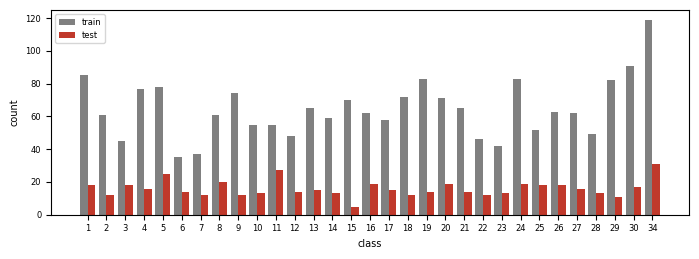

In [6]:
with plt.rc_context({"font.size": 7, "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 6}):
    fig, ax = plt.subplots(figsize=(7, 2.6))
    x = np.arange(len(classes)); w = 0.4
    ax.bar(x - w/2, ctr, w, color="grey", label="train")
    ax.bar(x + w/2, cte, w, color=COLOR_HIGHLIGHT, label="test")
    ax.set_xticks(x); ax.set_xticklabels(classes); ax.set_xlabel("class"); ax.set_ylabel("count"); ax.legend()
    fig.tight_layout(); fig.savefig(fig_dir / "split_counts.png", dpi=200); plt.show()

## 6. Summary

In [7]:
summary = {
    "n_train": int(len(train_idx)), "n_test": int(len(test_idx)), "n_groups": int(n_groups),
    "groups_shared_between_splits": int(len(shared)),
    "naive_split_test_rows_with_T_in_train": {"count": leak_n, "fraction": round(leak_frac, 4)},
    "test_fraction_per_class": {"min": round(float(frac.min()), 4), "max": round(float(frac.max()), 4)},
    "largest_group": {"size": int(big_rows.sum()), "label": int(Y[big_rows][0]), "split": big_split},
    "max_abs_diff_train_vs_full_mean": {"I": dI, "T": dT},
}
json.dump(summary, open(res_dir / "step3_summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2))

{
  "n_train": 2005,
  "n_test": 495,
  "n_groups": 2075,
  "groups_shared_between_splits": 0,
  "naive_split_test_rows_with_T_in_train": {
    "count": 112,
    "fraction": 0.224
  },
  "test_fraction_per_class": {
    "min": 0.0667,
    "max": 0.3293
  },
  "largest_group": {
    "size": 30,
    "label": 9,
    "split": "train"
  },
  "max_abs_diff_train_vs_full_mean": {
    "I": 0.010775066912174225,
    "T": 0.016170501708984375
  }
}
